In [1]:


import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
data = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.shape

(7043, 21)

In [5]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'],errors='coerce')

In [6]:
data.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [7]:
data[['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [8]:
data['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [9]:
cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

for col in cols:
    print(col, ":", data[col].unique())

gender : ['Female' 'Male']
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn : ['No' 'Yes']


In [10]:
data['customerID'].duplicated().sum()

np.int64(0)

In [11]:
data.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
data['customerID'].count()

np.int64(7043)

In [13]:
data[(data['Contract']=='Month-to-month')&(data["Churn"]=="Yes")].shape[0]

1655

In [14]:
pd.crosstab(data['Contract'],data['Churn'],margins=True)

Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


In [15]:
pd.crosstab(data["Contract"],data["Churn"],normalize='index')*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [16]:
labels=["very new customers","somewhat new","medium-tenure","long-tenure customers"]
data["tenure_group"] = pd.cut(data["tenure"],bins=4,labels=labels)
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,very new customers
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,somewhat new
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,very new customers
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,medium-tenure
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,very new customers


In [17]:
pd.crosstab(data["tenure_group"],data["Churn"],normalize='index')*100

Churn,No,Yes
tenure_group,,
very new customers,55.596196,44.403804
somewhat new,77.293578,22.706422
medium-tenure,81.979695,18.020305
long-tenure customers,92.028587,7.971413


In [18]:
pd.crosstab(data["Contract"],data["tenure_group"],normalize='index')*100

tenure_group,very new customers,somewhat new,medium-tenure,long-tenure customers
Contract,,,,
Month-to-month,62.245161,20.774194,11.329032,5.651613
One year,14.528174,24.236253,30.006789,31.228785
Two year,6.371681,8.613569,17.758112,67.256637


In [19]:
pd.crosstab(index= [data["Contract"],data["tenure_group"]],
            columns = data["Churn"],normalize="index")*100

Churn                                         No        Yes
Contract       tenure_group                                
Month-to-month very new customers      50.456053  49.543947
               somewhat new            67.080745  32.919255
               medium-tenure           66.742597  33.257403
               long-tenure customers   77.625571  22.374429
One year       very new customers      91.121495   8.878505
               somewhat new            91.596639   8.403361
               medium-tenure           86.877828  13.122172
               long-tenure customers   87.173913  12.826087
Two year       very new customers     100.000000   0.000000
               somewhat new            98.630137   1.369863
               medium-tenure           97.009967   2.990033
               long-tenure customers   96.754386   3.245614

In [20]:
data["monthlyCharges_group"] = pd.cut(data["MonthlyCharges"],bins=4)
pd.crosstab(data["Churn"],data["monthlyCharges_group"],normalize='columns')*100

monthlyCharges_group,"(18.15, 43.375]","(43.375, 68.5]","(68.5, 93.625]","(93.625, 118.75]"
Churn,,,,
No,87.677725,78.503994,63.187773,66.418416
Yes,12.322275,21.496006,36.812227,33.581584


In [21]:
pd.crosstab(data["Churn"],data["monthlyCharges_group"])

monthlyCharges_group,"(18.15, 43.375]","(43.375, 68.5]","(68.5, 93.625]","(93.625, 118.75]"
Churn,,,,
No,1665,1081,1447,981
Yes,234,296,843,496


In [22]:
ct_pct=pd.crosstab(index=[data["InternetService"],data["monthlyCharges_group"]],
           columns=data["Churn"],normalize="index")*100

In [23]:
ct_counts=pd.crosstab(index=[data["InternetService"],data["monthlyCharges_group"]],
           columns=data["Churn"],margins=True, margins_name="Total")

In [24]:
side_by_side = pd.concat([ct_pct,ct_counts],axis=1, keys=["Percentage","counts"])
side_by_side

Percentage             counts        \
Churn                                         No         Yes     No   Yes   
InternetService monthlyCharges_group                                        
DSL             (18.15, 43.375]        67.560322   32.439678    252   121   
                (43.375, 68.5]         78.675400   21.324600   1081   293   
                (68.5, 93.625]         93.313522    6.686478    628    45   
                (93.625, 118.75]      100.000000    0.000000      1     0   
Fiber optic     (43.375, 68.5]          0.000000  100.000000      0     3   
                (68.5, 93.625]         50.649351   49.350649    819   798   
                (93.625, 118.75]       66.395664   33.604336    980   496   
No              (18.15, 43.375]        92.595020    7.404980   1413   113   
Total                                        NaN         NaN   5174  1869   

                                            
Churn                                Total  
InternetService monthlyCharges_group        
DSL             (18.15, 43.375]        373  
                (43.375, 68.5]        1374  
                (68.5, 93.625]         673  
                (93.625, 118.75]         1  
Fiber optic     (43.375, 68.5]           3  
                (68.5, 93.625]        1617  
                (93.625, 118.75]      1476  
No              (18.15, 43.375]       1526  
Total                                 7043

In [25]:
pct_IC = pd.crosstab(index=[data["InternetService"],data["Contract"]],
           columns = data["Churn"],normalize = "index")*100
count_IC = pd.crosstab(index=[data["InternetService"],data["Contract"]],
                      columns = data["Churn"], margins = True, margins_name = "Total")

s_to_s = pd.concat([pct_IC,count_IC], axis=1, keys=["percentage","count"])
s_to_s

percentage            count            
Churn                                  No        Yes    No   Yes Total
InternetService Contract                                              
DSL             Month-to-month  67.784137  32.215863   829   394  1223
                One year        90.701754   9.298246   517    53   570
                Two year        98.089172   1.910828   616    12   628
Fiber optic     Month-to-month  45.394737  54.605263   966  1162  2128
                One year        80.705009  19.294991   435   104   539
                Two year        92.773893   7.226107   398    31   429
No              Month-to-month  81.106870  18.893130   425    99   524
                One year        97.527473   2.472527   355     9   364
                Two year        99.216301   0.783699   633     5   638
Total                                 NaN        NaN  5174  1869  7043

In [26]:
pct_ICM =  pd.crosstab(index = [data["InternetService"],data["Contract"],data["monthlyCharges_group"]],
           columns = data["Churn"] , normalize = "index") * 100
count_ICM = pd.crosstab(index = [data["InternetService"],data["Contract"],data["monthlyCharges_group"]],
           columns = data["Churn"], margins =True, margins_name = "total")
side_t0 = pd.concat([pct_ICM, count_ICM], axis=1, keys=["percentage", "count"])
side_t0

percentage              \
Churn                                                        No         Yes   
InternetService Contract       monthlyCharges_group                           
DSL             Month-to-month (18.15, 43.375]        57.037037   42.962963   
                               (43.375, 68.5]         68.920522   31.079478   
                               (68.5, 93.625]         85.454545   14.545455   
                One year       (18.15, 43.375]        92.187500    7.812500   
                               (43.375, 68.5]         91.749175    8.250825   
                               (68.5, 93.625]         88.669951   11.330049   
                Two year       (18.15, 43.375]       100.000000    0.000000   
                               (43.375, 68.5]         97.368421    2.631579   
                               (68.5, 93.625]         98.333333    1.666667   
                               (93.625, 118.75]      100.000000    0.000000   
Fiber optic     Month-to-month (43.375, 68.5]          0.000000  100.000000   
                               (68.5, 93.625]         45.238095   54.761905   
                               (93.625, 118.75]       45.911047   54.088953   
                One year       (68.5, 93.625]         89.208633   10.791367   
                               (93.625, 118.75]       77.750000   22.250000   
                Two year       (68.5, 93.625]         98.000000    2.000000   
                               (93.625, 118.75]       92.084433    7.915567   
No              Month-to-month (18.15, 43.375]        81.106870   18.893130   
                One year       (18.15, 43.375]        97.527473    2.472527   
                Two year       (18.15, 43.375]        99.216301    0.783699   
total                                                       NaN         NaN   

                                                    count              
Churn                                                  No   Yes total  
InternetService Contract       monthlyCharges_group                    
DSL             Month-to-month (18.15, 43.375]        154   116   270  
                               (43.375, 68.5]         581   262   843  
                               (68.5, 93.625]          94    16   110  
                One year       (18.15, 43.375]         59     5    64  
                               (43.375, 68.5]         278    25   303  
                               (68.5, 93.625]         180    23   203  
                Two year       (18.15, 43.375]         39     0    39  
                               (43.375, 68.5]         222     6   228  
                               (68.5, 93.625]         354     6   360  
                               (93.625, 118.75]         1     0     1  
Fiber optic     Month-to-month (43.375, 68.5]           0     3     3  
                               (68.5, 93.625]         646   782  1428  
                               (93.625, 118.75]       320   377   697  
                One year       (68.5, 93.625]         124    15   139  
                               (93.625, 118.75]       311    89   400  
                Two year       (68.5, 93.625]          49     1    50  
                               (93.625, 118.75]       349    30   379  
No              Month-to-month (18.15, 43.375]        425    99   524  
                One year       (18.15, 43.375]        355     9   364  
                Two year       (18.15, 43.375]        633     5   638  
total                                                5174  1869  7043

In [27]:
pct_ICM =  pd.crosstab(index = [data["InternetService"],data["Contract"],data["TechSupport"]],
           columns = data["Churn"] , normalize = "index") * 100
count_ICM = pd.crosstab(index = [data["InternetService"],data["Contract"],data["TechSupport"]],
           columns = data["Churn"], margins =True, margins_name = "total")
side_t0 = pd.concat([pct_ICM, count_ICM], axis=1, keys=["percentage", "count"])
side_t0

percentage             \
Churn                                                      No        Yes   
InternetService Contract       TechSupport                                 
DSL             Month-to-month No                   64.140271  35.859729   
                               Yes                  77.286136  22.713864   
                One year       No                   90.163934   9.836066   
                               Yes                  91.104294   8.895706   
                Two year       No                   96.521739   3.478261   
                               Yes                  98.440546   1.559454   
Fiber optic     Month-to-month No                   42.483296  57.516704   
                               Yes                  61.144578  38.855422   
                One year       No                   81.469649  18.530351   
                               Yes                  79.646018  20.353982   
                Two year       No                   91.735537   8.264463   
                               Yes                  93.181818   6.818182   
No              Month-to-month No internet service  81.106870  18.893130   
                One year       No internet service  97.527473   2.472527   
                Two year       No internet service  99.216301   0.783699   
total                                                     NaN        NaN   

                                                   count              
Churn                                                 No   Yes total  
InternetService Contract       TechSupport                            
DSL             Month-to-month No                    567   317   884  
                               Yes                   262    77   339  
                One year       No                    220    24   244  
                               Yes                   297    29   326  
                Two year       No                    111     4   115  
                               Yes                   505     8   513  
Fiber optic     Month-to-month No                    763  1033  1796  
                               Yes                   203   129   332  
                One year       No                    255    58   313  
                               Yes                   180    46   226  
                Two year       No                    111    10   121  
                               Yes                   287    21   308  
No              Month-to-month No internet service   425    99   524  
                One year       No internet service   355     9   364  
                Two year       No internet service   633     5   638  
total                                               5174  1869  7043

In [28]:
pct_ICM =  pd.crosstab(index = [data["InternetService"],data["Contract"],data["OnlineSecurity"]],
           columns = data["Churn"] , normalize = "index") * 100
count_ICM = pd.crosstab(index = [data["InternetService"],data["Contract"],data["OnlineSecurity"]],
           columns = data["Churn"], margins =True, margins_name = "total")
side_t0 = pd.concat([pct_ICM, count_ICM], axis=1, keys=["percentage", "count"])
side_t0

percentage             \
Churn                                                      No        Yes   
InternetService Contract       OnlineSecurity                              
DSL             Month-to-month No                   63.593932  36.406068   
                               Yes                  77.595628  22.404372   
                One year       No                   87.083333  12.916667   
                               Yes                  93.333333   6.666667   
                Two year       No                   97.222222   2.777778   
                               Yes                  98.347107   1.652893   
Fiber optic     Month-to-month No                   41.882751  58.117249   
                               Yes                  62.994350  37.005650   
                One year       No                   79.179811  20.820189   
                               Yes                  82.882883  17.117117   
                Two year       No                   89.759036  10.240964   
                               Yes                  94.676806   5.323194   
No              Month-to-month No internet service  81.106870  18.893130   
                One year       No internet service  97.527473   2.472527   
                Two year       No internet service  99.216301   0.783699   
total                                                     NaN        NaN   

                                                   count              
Churn                                                 No   Yes total  
InternetService Contract       OnlineSecurity                         
DSL             Month-to-month No                    545   312   857  
                               Yes                   284    82   366  
                One year       No                    209    31   240  
                               Yes                   308    22   330  
                Two year       No                    140     4   144  
                               Yes                   476     8   484  
Fiber optic     Month-to-month No                    743  1031  1774  
                               Yes                   223   131   354  
                One year       No                    251    66   317  
                               Yes                   184    38   222  
                Two year       No                    149    17   166  
                               Yes                   249    14   263  
No              Month-to-month No internet service   425    99   524  
                One year       No internet service   355     9   364  
                Two year       No internet service   633     5   638  
total                                               5174  1869  7043

In [29]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,monthlyCharges_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,very new customers,"(18.15, 43.375]"
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,somewhat new,"(43.375, 68.5]"
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,very new customers,"(43.375, 68.5]"
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,medium-tenure,"(18.15, 43.375]"
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,very new customers,"(68.5, 93.625]"


In [30]:
data = data.drop(columns=["monthlyCharges_group","tenure_group"])

In [31]:
y = data["Churn"]
data = data.drop(columns=["customerID","Churn"])

In [32]:
x = data
x.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [33]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

In [34]:
y = y.map({'Yes':1, 'No':0})

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train,X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state = 42,
    stratify = y
)

train_median = X_train["TotalCharges"].median()

X_train["TotalCharges"] = X_train["TotalCharges"].fillna(train_median)
X_test["TotalCharges"] = X_test["TotalCharges"].fillna(train_median)

X_train_encoded = pd.get_dummies(X_train, drop_first=True).astype("float32")
X_test_encoded = pd.get_dummies(X_test, drop_first=True).astype("float32")

X_test_encoded = X_test_encoded.reindex(columns = X_train_encoded.columns, fill_value=0)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train_encoded)
x_test_scaled = scaler.transform(X_test_encoded)

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
roc_auc_score,
confusion_matrix,
classification_report
)

model = LogisticRegression(max_iter=1000)

model.fit(x_train_scaled,y_train)


y_pred = model.predict(x_test_scaled)
y_proba = model.predict_proba(x_test_scaled)[:, 1]  


print("=== Classification Report ===")
print(classification_report(y_test, y_pred))


print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))


print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

=== Confusion Matrix ===
[[925 110]
 [162 212]]
Accuracy:  0.8070
Precision: 0.6584
Recall:    0.5668
F1 Score:  0.6092
ROC-AUC:   0.8416


In [37]:
top_twoHundred = np.sort(y_proba)[-200:][::-1]


In [38]:
y_pred_40 = (y_proba >= 0.40).astype(int)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred_40))


print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_40))


print(f"Accuracy:  {accuracy_score(y_test, y_pred_40):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_40):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_40):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_40):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

=== Confusion Matrix ===
[[844 191]
 [124 250]]
Accuracy:  0.7764
Precision: 0.5669
Recall:    0.6684
F1 Score:  0.6135


In [39]:
y_pred_40 = (y_proba >= 0.30).astype(int)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred_40))


print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_40))


print(f"Accuracy:  {accuracy_score(y_test, y_pred_40):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_40):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_40):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_40):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.89      0.75      0.81      1035
           1       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409

=== Confusion Matrix ===
[[773 262]
 [ 92 282]]
Accuracy:  0.7488
Precision: 0.5184
Recall:    0.7540
F1 Score:  0.6144


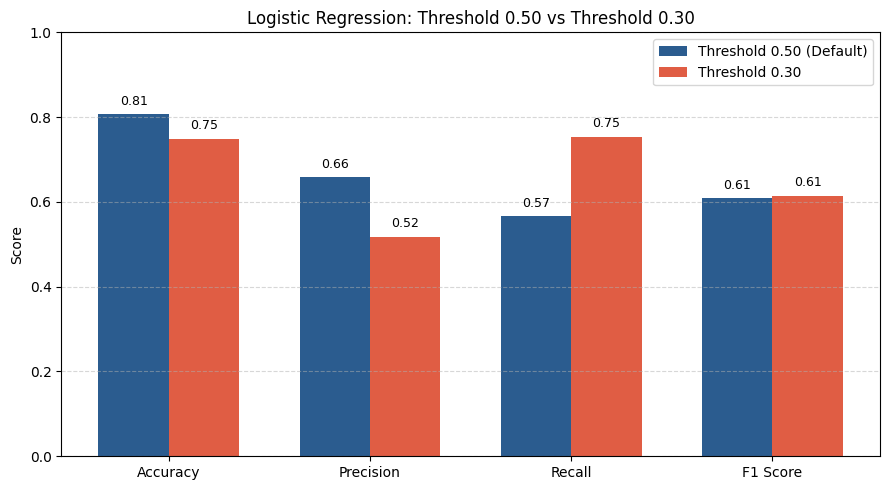

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Performance metrics for both threshold levels
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
t_50 = [0.8070, 0.6584, 0.5668, 0.6092]
t_40 = [0.7807, 0.5744, 0.6711, 0.6189]
t_30 = [0.7488, 0.5184, 0.7540, 0.6144]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
bar1 = plt.bar(x - width/2, t_50, width, label='Threshold 0.50 (Default)', color='#2b5c8f')
bar2 = plt.bar(x + width/2, t_30, width, label='Threshold 0.30', color='#e05d44')

plt.ylabel('Score')
plt.title('Logistic Regression: Threshold 0.50 vs Threshold 0.30')
plt.xticks(x, metrics)
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add score labels on top of bars
for bar in bar1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.015, f'{yval:.2f}', ha='center', va='bottom', fontsize=9)

for bar in bar2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.015, f'{yval:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [41]:
results = pd.DataFrame(
    {
        "Actual_Churn" : y_test,
        "Churn_Probability" : y_proba
    },
    index = X_test.index
)

ranked_results = results.sort_values(
    by = "Churn_Probability",
    ascending = False
)

top_200 = ranked_results.head(200)

count = top_200["Actual_Churn"].sum()
precision = (count / 200)*100
print(precision)

72.0


In [42]:
data.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

In [43]:
X_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55


In [44]:
numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_cols = [
    col for col in X_train.columns
    if col not in numerical_cols
]

categorical_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [46]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

In [47]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [48]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [49]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

In [50]:
y_train

3738    0
3151    0
4860    0
3867    0
3810    0
       ..
6303    0
6227    1
4673    1
2710    0
5639    0
Name: Churn, Length: 5634, dtype: int64

In [51]:
cv_scores = cross_val_score(
    model_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print(cv_scores)
print("Mean CV Accuracy:" ,cv_scores.mean())

[0.79769299 0.78172138 0.80212955 0.81632653 0.81083481]
Mean CV Accuracy: 0.8017410532055897


In [52]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    model_pipeline,
    X_train,
    y_train,
    cv = cv,
    scoring = {
        "accuracy": "accuracy",
        "precision": "precision",
        "recall" : "recall",
        "f1" : "f1",
        "roc_auc": "roc_auc"
    }
)



In [53]:
print(cv_results.keys())

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])


In [54]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric}: {cv_results['test_' + metric]}")

accuracy: [0.79769299 0.78172138 0.80212955 0.81632653 0.81083481]
precision: [0.6437247  0.60728745 0.65833333 0.66428571 0.68695652]
recall: [0.53177258 0.50167224 0.52842809 0.62207358 0.52842809]
f1: [0.58241758 0.54945055 0.58627087 0.64248705 0.5973535 ]
roc_auc: [0.84740197 0.82518419 0.84188034 0.86286212 0.85290347]


In [55]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    score = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"mean: {score.mean():.4f}, "
        f"std: {score.std():.4f}"
    )


accuracy: mean: 0.8017, std: 0.0119
precision: mean: 0.6521, std: 0.0264
recall: mean: 0.5425, std: 0.0413
f1: mean: 0.5916, std: 0.0300
roc_auc: mean: 0.8460, std: 0.0125


In [56]:
model_pipeline.fit(X_train,y_train)
ypred = model_pipeline.predict(X_test)

In [57]:
y_pred1 = model_pipeline.predict(X_test)
y_proba1 = model_pipeline.predict_proba(X_test)[:,1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred1):.4f}")
print(f"Precision: {precision_score(y_test, y_pred1):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred1):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred1):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba1):.4f}")

Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1 Score:  0.6040
ROC-AUC:   0.8419


In [58]:
from sklearn.ensemble import RandomForestClassifier

model_pipeline2 = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
])

model_pipeline2.fit(X_train,y_train)

y_pred2 = model_pipeline2.predict(X_test)
y_proba2 = model_pipeline2.predict_proba(X_test)[:,1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred2):.4f}")
print(f"Precision: {precision_score(y_test, y_pred2):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred2):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred2):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba2):.4f}")

Accuracy:  0.7779
Precision: 0.6034
Recall:    0.4759
F1 Score:  0.5321
ROC-AUC:   0.8162


In [59]:
from sklearn.neural_network import MLPClassifier

model_pipeline3 = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(max_iter=1000))
])

model_pipeline3.fit(X_train,y_train)

y_pred3 = model_pipeline3.predict(X_test)
y_proba3 = model_pipeline3.predict_proba(X_test)[:,1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred3):.4f}")
print(f"Precision: {precision_score(y_test, y_pred3):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred3):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred3):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba3):.4f}")

Accuracy:  0.7651
Precision: 0.5646
Recall:    0.5027
F1 Score:  0.5318
ROC-AUC:   0.7987


In [60]:
from xgboost import XGBClassifier

model_pipeline4 = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(n_estimators=100))
])

model_pipeline4.fit(X_train,y_train)

y_pred4 = model_pipeline4.predict(X_test)
y_proba4 = model_pipeline4.predict_proba(X_test)[:,1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred4):.4f}")
print(f"Precision: {precision_score(y_test, y_pred4):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred4):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred4):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba4):.4f}")

Accuracy:  0.7850
Precision: 0.6060
Recall:    0.5428
F1 Score:  0.5726
ROC-AUC:   0.8254


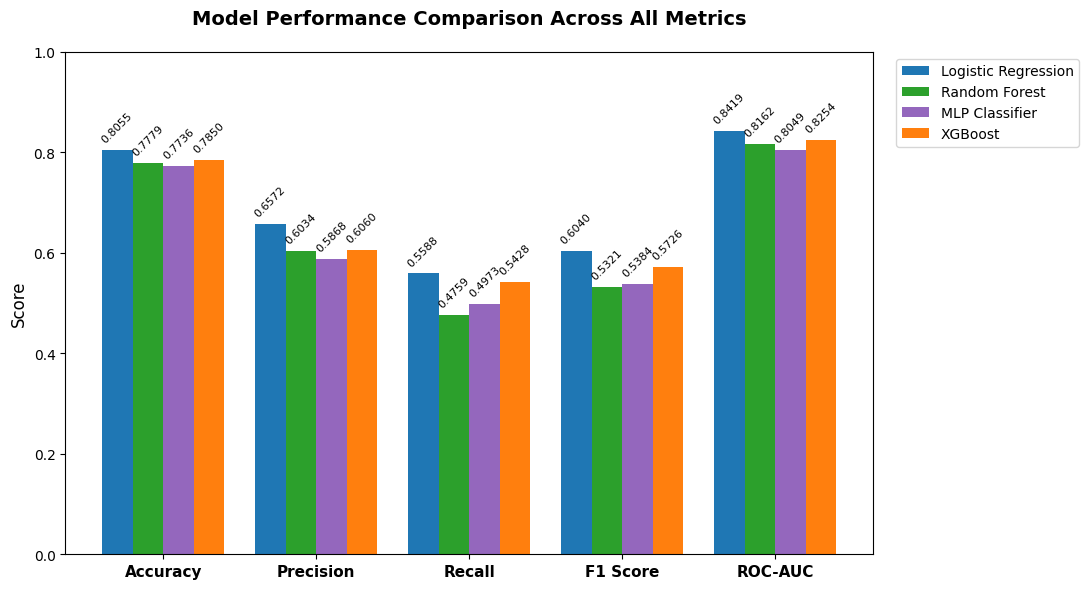

In [61]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Model metric results
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
scores = {
    'Logistic Regression': [0.8055, 0.6572, 0.5588, 0.6040, 0.8419],
    'Random Forest': [0.7779, 0.6034, 0.4759, 0.5321, 0.8162],
    'MLP Classifier': [0.7736, 0.5868, 0.4973, 0.5384, 0.8049],
    'XGBoost': [0.7850, 0.6060, 0.5428, 0.5726, 0.8254]
}

df = pd.DataFrame(scores, index=metrics)

# Create bar plot
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(metrics))
width = 0.2
colors = ['#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e']

for i, model in enumerate(scores.keys()):
    bars = ax.bar(x + (i - 1.5) * width, df[model], width, label=model, color=colors[i])
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, rotation=45)

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison Across All Metrics', fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.0)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()

plt.show()

In [62]:
from sklearn.model_selection import cross_validate

models = [model_pipeline, model_pipeline2, model_pipeline3, model_pipeline4]
names = ["Logistic Regression", "Random Forest", "Neural Net", "XGBoost"]

for model, name in zip(models, names):
    cv_results = cross_validate(
        model,  
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        }
    )

    print(f"=== {name} ===")
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        score = cv_results[f"test_{metric}"]
        print(f"{metric:10s} -> mean: {score.mean():.4f}, std: {score.std():.4f}")
    print("=========================X============================\n")

=== Logistic Regression ===
accuracy   -> mean: 0.8017, std: 0.0119
precision  -> mean: 0.6521, std: 0.0264
recall     -> mean: 0.5425, std: 0.0413
f1         -> mean: 0.5916, std: 0.0300
roc_auc    -> mean: 0.8460, std: 0.0125
=========================X============================

=== Random Forest ===
accuracy   -> mean: 0.7845, std: 0.0132
precision  -> mean: 0.6226, std: 0.0343
recall     -> mean: 0.4789, std: 0.0269
f1         -> mean: 0.5412, std: 0.0277
roc_auc    -> mean: 0.8183, std: 0.0122
=========================X============================

=== Neural Net ===
accuracy   -> mean: 0.7758, std: 0.0070
precision  -> mean: 0.5893, std: 0.0188
recall     -> mean: 0.5197, std: 0.0575
f1         -> mean: 0.5499, std: 0.0325
roc_auc    -> mean: 0.7959, std: 0.0081
=========================X============================

=== XGBoost ===
accuracy   -> mean: 0.7803, std: 0.0120
precision  -> mean: 0.6021, std: 0.0284
recall     -> mean: 0.5084, std: 0.0235
f1         -> mean: 0.5511,